**Aprendizaje Automático** - 2025
# Clase 5: Clasificación

Temas que veremos en esta notebook:

- Clasificación binaria.
- Regresión logística y función sigmoidea
- Cross entropy
- Support Vector Machines
- K-Nearest Neighbours
- Métricas
- Clasificación multiclase

In [ ]:
# Imports necesarios
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LassoCV, RidgeCV, ElasticNet, ElasticNetCV
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, log_loss, confusion_matrix
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

# Clasificación Binaria: Modelos

## Ejemplo: Dataset Breast Cancer Detection
Para la primer parte vamos a usar el dataset de [Detección de cancer de mama](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data) compuesto de distintas fotos de tejido las cuales se clasifican como potencial cáncer. Para estas fotos se extraen las siguientes características:

    Descripción del dataset:

    Se calculan diez características de valor real para cada núcleo celular:

    * radio
    * textura
    * perímetro
    * área
    * suavidad
    * compacidad
    * concavidad
    * puntos cóncavos
    * simetría
    * dimensión fractal

    Se calculan el promedio, el error estándar y el "peor" o el más grande (promedio de los tres valores más grandes) de estas características para cada imagen, lo que resulta en 30 características.

In [ ]:
from sklearn.datasets import load_breast_cancer

# cargar el conjunto de datos
data = load_breast_cancer()

# dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

In [ ]:
X_train.shape

(455, 30)

---
## Regresión logística

La [regresión logística](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression) es una técnica de aprendizaje supervisado utilizada para predecir la probabilidad de una variable categórica binaria en función de una o más variables predictoras. En scikit-learn, se puede utilizar la clase `LogisticRegression` para construir modelos de regresión logística.

La RL puede verse como un modelo lineal generalizado, en el que a una combinación lineal de atributos o transformaciones se le aplica una función no lineal (función de activación), que en este caso particular es la **función sigmoidea** o función logítica. La función sigmoidea se utiliza para transformar la variable dependiente en un rango entre 0 y 1, y se define como:

$ \sigma (z) = \frac{1}{1+e^{-z}} $

![](https://upload.wikimedia.org/wikipedia/commons/thumb/8/88/Logistic-curve.svg/600px-Logistic-curve.svg.png)

donde $z$ es la entrada que en la regresion logística es en realidad una combinación lineal:

$z = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_px_p$

quedando el modelo $f$ para un dato $x$:

\begin{equation}
f(x) = \sigma(\beta_0 + \sum_{j=1}^p \beta_j x_j) = \frac{1}{1+e^{-(\beta_0 + \sum_{j=1}^p \beta_j x_j)}}
\end{equation}

En el caso de clasificación binaria se interpreta como la probabilidad de la etiqueta correspondiente a los features $x$ de pertenecer a la clase de interés o clase positiva (por ej: si un tipo de cancer es maligno) o de pertenecer a la clase negativa ($\mathcal{C}_P$ o $\mathcal{C}_N$). Volvemos a usar $y$ para la clase de $x$ y la predicción del modelo será $\hat{y}$:

$$
\hat{y} = \max \{ P(y\in \mathcal{C}_P|x), P(y\in \mathcal{C}_N|x) \}
$$

Pero esto se puede reescribir como:

$$
\hat{y} = \max \{ P(y\in \mathcal{C}_P|x), 1 - P(y\in \mathcal{C}_P|x) \}
$$

Nuestro modelo $f$ justamente predecirá esto:$f(x) = P(y\in \mathcal{C}_P|x)$, quedando

$$
\hat{y}=  \max \{ f(x), 1 - f(x) \}
$$

por lo tanto si la predicción es mayor a $0.5$ se predice clase positiva y sino clase negativa.

In [ ]:
#@title Ejemplo
# NOTA: Este codigo puede ser medio complejo, por lo cual no es necesario que entiendan todo lo que hace
from sklearn.linear_model import LogisticRegression

# Generamos los puntos al azar
np.random.seed(42)
low_x =-2
high_x = 4
print('Creando una distribución de datos...')

#crea una distribución uniforme
X = np.random.uniform(low=low_x, high=high_x, size=(100,1))
#La función numpy.where acepta como argumentos de entrada una condición y dos
#estructuras tipo array, x e y, y devuelve valores de x o de y en función de
#que se cumpla o no la condición: Si se cumple, se devuelve el valor de x. Si no se cumple, el de y.
a = np.random.binomial(1, 0.9, size=(100,1))
b = np.random.binomial(1, 0.1, size=(100,1))
y = np.where(X<0, a, b)

# Instanciamos el modelo
print('Ajustando una regresión logística...')
lr = LogisticRegression()
# La función numpy.ravel() devuelve un array 1D con todos los elementos del array de entrada y con el mismo tipo
# Ajustamos una regresión logística a los datos
lr.fit(X, y.ravel())

# Creamos una cuadrícula de valores de x para hacer predicciones
x_grid, y_grid = np.meshgrid(np.linspace(low_x, high_x, 100), np.linspace(-0.1, 1.1, 100))
X_test_ = x_grid.ravel().reshape(-1,1)

# Creamos el rango de valores de x para la recta de decisión (se podria extrar de x_grid)
x_range = np.linspace(low_x, high_x, 100)

# Hacemos predicciones en la cuadrícula de valores de x
z_proba = lr.predict_proba(X_test_)[:,1]
z_predict = lr.predict(X_test_)

# Hacemos predicciones en la cuadrícula de valores de x
y_proba = lr.predict_proba(x_range.reshape(-1,1))[:, 1]

# Calculamos la predicción del modelo para cada punto en el rango de valores de x
y_decision = lr.predict(x_range.reshape(-1, 1))

print(f"La función para tomar la decisión es: f(x) = 1/(1 + exp(-({lr.intercept_[0]:0.2f}+{lr.coef_[0][0]:0.2f}*X)))")



Creando una distribución de datos...
Ajustando una regresión logística...
La función para tomar la decisión es: f(x) = 1/(1 + exp(-(0.46+-1.45*X)))


In [ ]:
y.ravel()

array([0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1])

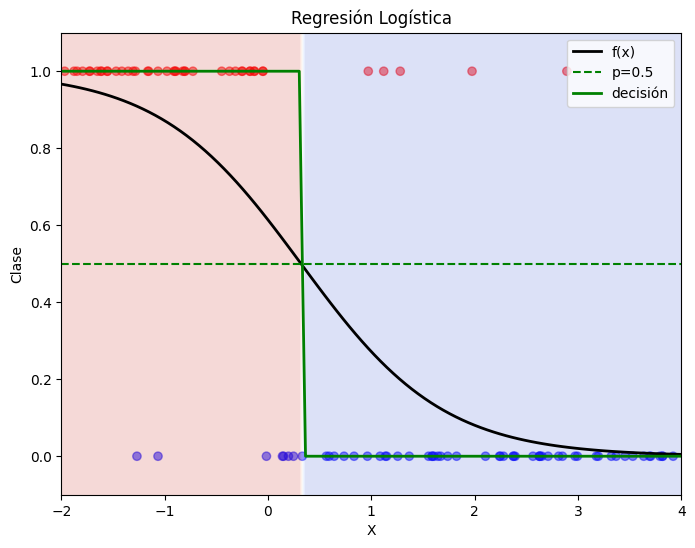

In [ ]:
#@title Gráfico
# Creamos el gráfico
fig, ax = plt.subplots(figsize=(8,6))
plt.scatter(X, y, color=['red' if i==1 else 'blue' for i in y], alpha=0.5)
plt.plot(x_range, y_proba, color='black', linewidth=2, label='f(x)')
plt.axhline(y=0.5, color='green', linestyle='--', label='p=0.5')
ax.contourf(x_grid, y_grid, z_predict.reshape(x_grid.shape), alpha=0.2, cmap='coolwarm')
plt.plot(x_range, y_decision, color='green', linewidth=2, label='decisión')
plt.xlabel('X')
plt.ylabel('Clase')
plt.title('Regresión Logística')
plt.legend()
plt.show()

Vamos a tratar de entrenar uno en nuestro dataset de Breast Cancer.

In [ ]:
from sklearn.linear_model import LogisticRegression

# crear el modelo de regresión logística
model = LogisticRegression(penalty=None, max_iter=10000)

# entrenar el modelo con los datos de entrenamiento
model.fit(X_train, y_train)

# hacer predicciones con los datos de prueba
y_pred = model.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))

Accuracy de la clasificación: 97.37%


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
model.intercept_

array([38.29955263])

In [ ]:
model.coef_

array([[ 1.21505525e+00, -1.39017838e-01,  5.27898398e-01,
        -4.25916817e-02, -2.42678221e+01,  2.07666314e+01,
        -3.24353714e+01, -5.77455300e+01,  2.36376358e+01,
         3.48987537e+00, -8.58733304e+00,  2.69687614e+00,
         1.32811761e+00, -2.97867111e-01, -1.05795961e+01,
         4.48016279e+01,  6.70767547e+01, -4.51176392e+00,
         1.63668549e+01,  8.18224721e+00, -2.18132249e+00,
        -5.85843655e-01, -7.01260427e-02,  1.25246684e-02,
        -5.91929277e+01,  1.21474916e+01, -1.63419788e+01,
        -6.44984487e+01, -2.46747072e+01,  9.16597302e+00]])

In [ ]:
model.coef_.shape

(1, 30)

**Mini Ejercicio**

¿Qué hiperparámetros tiene este modelo? Revisar la documentación.

In [ ]:
help(LogisticRegression)

Help on class LogisticRegression in module sklearn.linear_model._logistic:

class LogisticRegression(sklearn.linear_model._base.LinearClassifierMixin, sklearn.linear_model._base.SparseCoefMixin, sklearn.base.BaseEstimator)
 |  LogisticRegression(
 |      penalty='l2',
 |      *,
 |      dual=False,
 |      tol=0.0001,
 |      C=1.0,
 |      fit_intercept=True,
 |      intercept_scaling=1,
 |      class_weight=None,
 |      random_state=None,
 |      solver='lbfgs',
 |      max_iter=100,
 |      multi_class='deprecated',
 |      verbose=0,
 |      warm_start=False,
 |      n_jobs=None,
 |      l1_ratio=None
 |  )
 |
 |  Logistic Regression (aka logit, MaxEnt) classifier.
 |
 |  This class implements regularized logistic regression using the
 |  'liblinear' library, 'newton-cg', 'sag', 'saga' and 'lbfgs' solvers. **Note
 |  that regularization is applied by default**. It can handle both dense
 |  and sparse input. Use C-ordered arrays or CSR matrices containing 64-bit
 |  floats for opti

---
### Función de Pérdida y Cross-Entropy

La **función de pérdida** es la función $J$ que depende de los parámetros de nuestro modelo ($\theta$) y mide la distancia de las predicciones de nuestro modelo a los datos reales y que nos permite optimizar los parametros. En el caso de la regresión logística la función de pérdida que se utiliza es la función de **entropía cruzada (cross-entropy)**, que se define como:

$ J(\theta) = -\frac{1}{N} \sum_{i=1}^{N} y^{(i)} \log(h_\theta(x^{(i)})) + (1 - y^{(i)}) \log(1 - h_\theta(x^{(i)})) $

donde $N$ es el número de ejemplos de entrenamiento, $y^{(i)}$ es la variable categórica binaria verdadera, $x^{(i)}$ es el vector de características del ejemplo $i$, y $h_\theta(x^{(i)})$ es la predicción del modelo para la observación $i$.

Para el caso binario, se puede definir una implementación:




```
import numpy as np

def BinaryCrossEntropy(y_true, y_pred):
  return -(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred)).mean()
```



También se la conoce como `log_loss` como en [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html#sklearn.metrics.log_loss) y puede ser usada en el caso multiclase.

 Veamos la aplicación de esta función costo como métrica al caso de Regresión Logística sobre el Dataset Breast Cancer


In [ ]:
from sklearn.metrics import log_loss

y_pred_prob = model.predict_proba(X_test)[:, 1]  # Obtener vector de probabilidades

loss = log_loss(y_test, y_pred_prob)

print('Log loss:', loss)

Log loss: 0.05335372249433497


# ¿Qué significa estos valores?

In [ ]:
def BinaryCrossEntropy(y_true, y_pred):

  return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

print(BinaryCrossEntropy(y_test, y_pred_prob))

0.05335372249433495


**Mini Ejercicio**

¿Cómo sería el gráfico de esta función costo en función de la probabilidad predicha? Separen los casos en los que la clase real es 0 y aquellos en los que es 1.

---
## Support Vector Machines (SVM)

Los modelos de SVM (**Máquinas de Vectores de Soporte**) son un conjunto de algoritmos de aprendizaje supervisado utilizados para la clasificación y regresión. En clasificación, el modelo de SVM se basa en la idea de encontrar el hiperplano que mejor separa los datos de diferentes clases. Este hiperplano es definido por un conjunto de vectores de soporte, que son los puntos más cercanos a la frontera de decisión.

![](https://upload.wikimedia.org/wikipedia/commons/thumb/7/72/SVM_margin.png/300px-SVM_margin.png)

El modelo de SVM se puede representar matemáticamente de la siguiente manera:

Para el caso de clasificación binaria, el objetivo es encontrar el hiperplano que mejor separa los datos de dos clases. Dado un conjunto de entrenamiento ${(\mathbf{x}_1, y_1),...,(\mathbf{x}_m, y_m)}$, donde $\mathbf{x}_i \in \mathbb{R}^n$ es el vector de características del $i$-ésimo ejemplo y $y_i \in {-1, 1}$ es su correspondiente etiqueta de clase, el hiperplano que mejor separa los datos se puede encontrar resolviendo el siguiente problema de optimización:

$\min_{\mathbf{w}, b} \frac{1}{2}||\mathbf{w}||^2$

sujeto a $y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \geq 1$ para todo $i=1,...,m$

La función costo que se minimiza permite encontrar el hiperplano que maximiza el margen (es decir, la distancia a los puntos más cercanos de cada clase), mientras que las restricciones aseguran que dicho hiperplano separa correctamente los datos de ambas clases. Podemos usar su implementación [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) de la librería scikit-learn para implementar SVM.

In [ ]:
from sklearn.svm import SVC

# crear el modelo SVM
model = SVC(kernel='linear', C=1, random_state=42)

# entrenar el modelo con los datos de entrenamiento
model.fit(X_train, y_train)

# hacer predicciones con los datos de prueba
y_pred = model.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))

Accuracy de la clasificación: 95.61%


---
## K-Vecinos más Cercanos (KNN)

El modelo de **K-Nearest Neighbors (KNN)** es un algoritmo de aprendizaje supervisado utilizado para clasificación y regresión. La idea principal del KNN es encontrar las $K$ observaciones más cercanas a la observación de prueba en el espacio de características y utilizar su etiqueta para predecir la respuesta de la observación de prueba, que en el problema de clasificación es la clase. La distancia entre las observaciones se calcula utilizando una métrica de distancia, como la distancia Euclidiana o la distancia Manhattan.

---
*Nota:*
La ecuación para la distancia Euclidiana entre dos vectores de observaciones $x$ y $y$ es: $d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$, también conocida como norma o distancia $L^2$.

---

Para predecir la clase $\hat{y}^*$ de una observación $x^*$, se utiliza el voto mayoritario de las $K$ observaciones más cercanas a la observación de prueba $x^*$ dentro del conjunto de entrenamiento. La ecuación para la clasificación de KNN es:

$\hat{y}^* = \underset{c}{\operatorname{argmax}}\sum_{i=1}^{k}w_{i}\cdot I(y_{i}=c)$

donde $c$ es una de las posibles clases, $w_i$ es el peso asignado a la $i$-ésima observación cercana (tipicamente 1 o 1/distancia) e $I(y_i = c)$ es una función indicadora que toma el valor 1 si la etiqueta de la $i$-ésima observación cercana es igual a $c$ y 0 en caso contrario.

Para implementar [KNN](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier) en Python utilizando la librería scikit-learn, podemos utilizar la clase `KNeighborsClassifier`.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# crear el modelo de KNN con k=5
model = KNeighborsClassifier(n_neighbors=12)

# entrenar el modelo con los datos de entrenamiento
model.fit(X_train, y_train)

# hacer predicciones con los datos de prueba
y_pred = model.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))

Accuracy de la clasificación: 98.25%


Text(0, 0.5, 'accuracy_score')

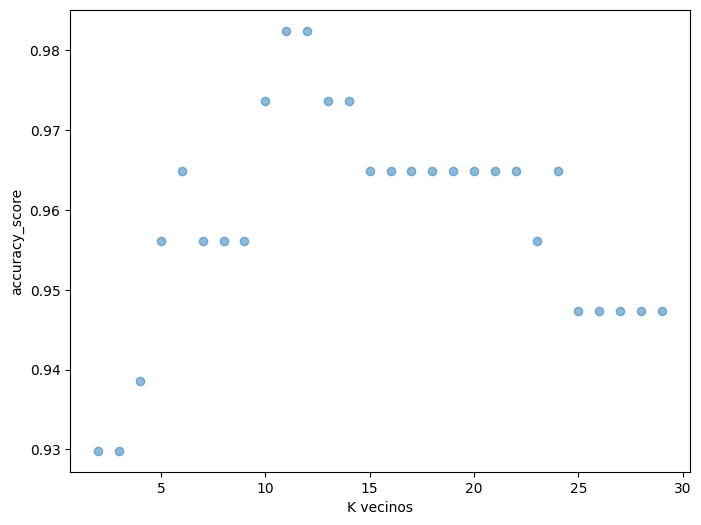

In [ ]:
x = range(2,30)
y = []
for i in x:
  model = KNeighborsClassifier(n_neighbors=i)
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  y.append(accuracy_score(y_test, y_pred))

fig, ax = plt.subplots(figsize=(8,6))
plt.scatter(x, y, alpha=0.5)
plt.xlabel('K vecinos')
plt.ylabel('accuracy_score')

---
# Métricas

Estuvimos viendo como calcular la performance de nuestro modelo a mano, pero scikit-learn nos provee ya un [módulo](https://scikit-learn.org/stable/api/sklearn.metrics.html#classification-metrics) completo con implementación de muchas métricas para clasificación (y muchos otros problemas). Veamos como calcular algunas como la matriz de confusión o el `f1-score`.

## Matriz de confusión

Recordemos como es la [matriz de confusión CM](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html), donde

$$CM_{i,j} = \text{# de observables en el grupo i que fueron detectados en el grupo j }$$

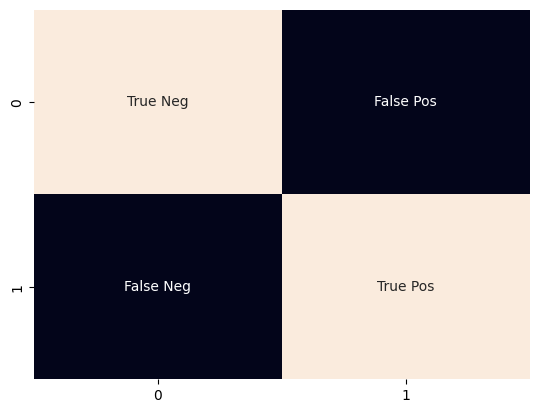

In [ ]:
#@title  Matriz de confusion en el caso binario
labels = ['True Neg','False Pos','False Neg','True Pos']
labels = np.asarray(labels).reshape(2,2)
sns.heatmap(np.array([[1,0],[0,1]]), annot=labels, fmt='', cbar=False);

In [ ]:
from sklearn.metrics import confusion_matrix
C = confusion_matrix(y_test, y_pred)
print('Confusion matrix:')
print(C)

Confusion matrix:
[[37  6]
 [ 0 71]]


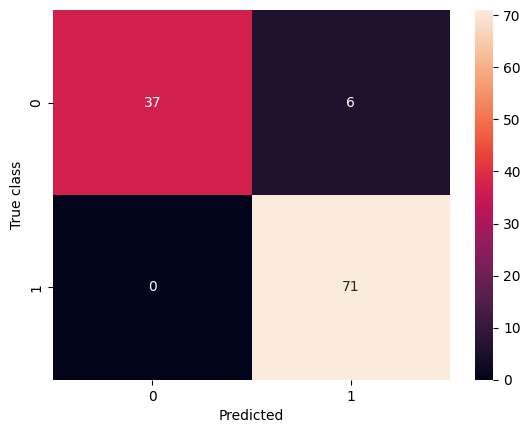

In [ ]:
# Con seaborn podemos verla asi
s= sns.heatmap(C, annot=True)
s.set(xlabel='Predicted', ylabel='True class');

## F-Score


### F1 (caso binario)
Por otro lado, el [F-Score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html#sklearn.metrics.f1_score) en el caso binario se define como

$$F1 = 2 * (precision * recall) / (precision + recall)
$$

El valor más alto posible de un puntaje F1 es 1, lo que indica un precision y recall perfectos, y el valor más bajo posible es 0, si el precision o el recall son cero.




In [ ]:
# f1_score nos devuelve la metrica para cada posible elección de clase positiva
from sklearn.metrics import f1_score
f1_score(y_test, y_pred, average=None)

array([0.925     , 0.95945946])

Una pequeña observación es que no es tan sencillo calcular metricas en el caso multiclase. En este caso tendremos tantos valores de precision y recall como clases tengamos, por lo tanto podremos calcular f1 de [distintas maneras](https://towardsdatascience.com/micro-macro-weighted-averages-of-f1-score-clearly-explained-b603420b292f). Según como querramos agruparlos tenemos distintas versiones de la métrica.

## Clasification Report

[`Classification Report`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html) es una herramienta de scikit-learn que nos permite ver muchas de las métricas de clasificación que vimos.

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.86      0.93        43
           1       0.92      1.00      0.96        71

    accuracy                           0.95       114
   macro avg       0.96      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



**Mini Ejercicio**

¿Qué significan cada uno de los valores? Investigar.

---
# Clasificación Multiclase

La clasificación puede separarse en:

**Clasificación binaria**

Cuando solo hay dos categorías para clasificar puntos de datos, se conoce como clasificación binaria. Por ejemplo, detectar si un paciente tiene tuberculosis (1) o no la tiene (0), o clasificar si una crítica de cine es positiva (1) o negativa (0).

**Clasificación multiclase**

Cuando el número de clases es mayor que dos, se conoce como clasificación multiclase. Por ejemplo, si tenemos que identificar el dígito en una imagen y clasificarlo en cualquier valor entre 0 y 9. En este caso, tenemos 10 clases. También podemos tener que calificar canciones entre 1 y 5 en base a su popularidad. En estos casos, cada punto de datos se asigna a una única etiqueta de clase.

**Clasificación multi-etiqueta**

Una sola entrada de datos puede tenes varias etiquetas asociadas. Por ejemplo, en la detección de objetos en imágenes, una imagen puede tener una casa y una planta. Esto se llama clasificación multi-etiqueta. **No trabajaremos este tipo de problemas en la materia.**

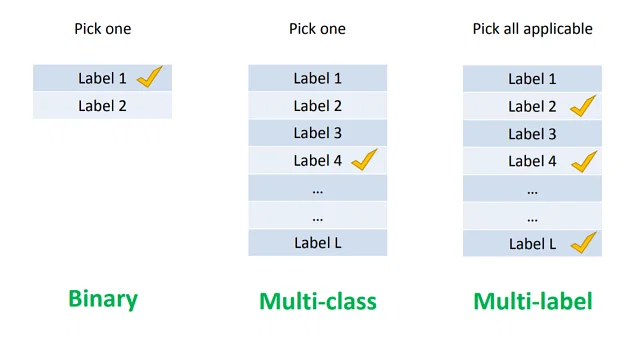

Los algoritmos utilizados para la clasificación multiclase se pueden categorizar principalmente en las siguientes categorías:

* Clasificador nativo de múltiples clases (Ej: Naive Bayes, KNN, Árboles)

* Transformación binaria (Lo veremos a continuación)

* Clasificación jerárquica (No lo veremos en la materia)

**Transformación binaria**

Existen algoritmos diseñados solo para tareas de clasificación binaria como la regresión logística y las máquinas de vectores de soporte (SVM). En el caso de multiclase, la tarea se divide en múltiples problemas de clasificación binaria utilizando principalmente dos estrategias:
* uno contra todos (one-vs-rest)
* uno contra uno (one-vs-one)


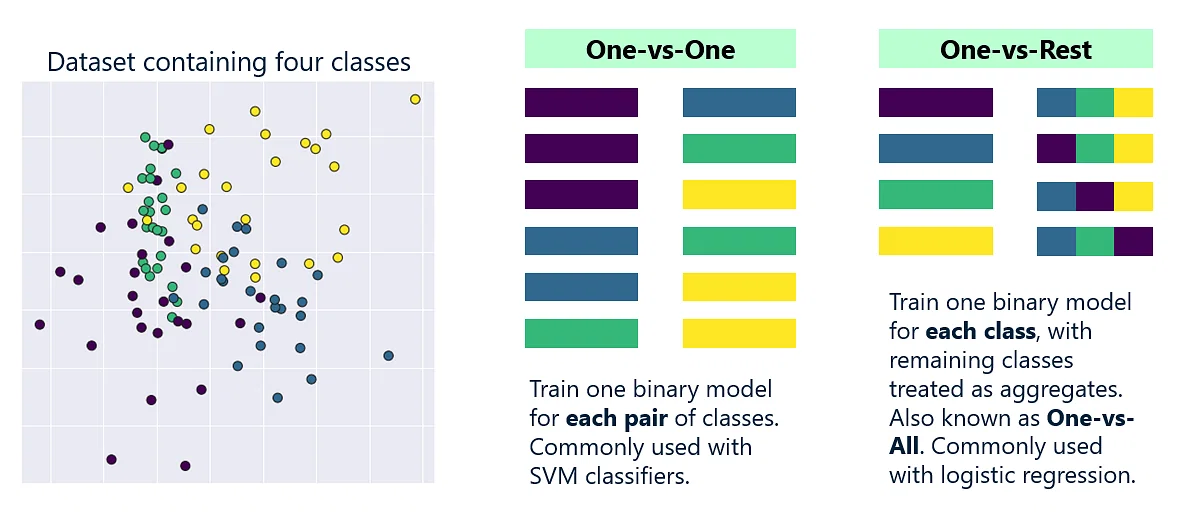

**Uno contra el resto (One-vs-Rest)**

Como su nombre indica, se entrena un clasificador binario para cada clase, donde la distribución de clases es la clase objetivo frente al resto de las clases.

Por ejemplo, si se está trabajando en un problema para predecir si la fruta dada es una manzana, pera o banana, se entrenarán tres clasificadores binarios.

* Clasificador A: [manzana] frente a [pera, banana]

* Clasificador B: [pera] frente a [manzana, bana]

* Clasificador C: [banana] frente a [manzana, pera]

Se utiliza el voto para predecir la clase final, es decir, el clasificador binario que predice la clase objetivo con la mayor confianza se da como salida final y se utiliza comúnmente con la regresión logística.

**Uno contra uno (One-vs-One)**

En este enfoque, se entrena un clasificador binario para cada par de clases, es decir, una clase frente a cada otra clase. El número de clasificadores binarios que se deben entrenar se puede calcular con la ayuda de esta fórmula sencilla:

(N * (N-1))/2 donde N = número total de clases

Por ejemplo, tomando el modelo anterior, los clasificadores totales que se deben entrenar son tres, que son los siguientes:

* Clasificador A: manzana frente a pera

* Clasificador B: manzana frente a banana

* Clasificador C: pera frente a banana

Cada clasificador binario predice una clase, y la clase predicha por la mayoría de los clasificadores se da como predicción final de clase. Esta estrategia funciona mejor para SVM u otros algoritmos basados en núcleos.

Probemos utilizar la regresión logística en una variable contra el resto.

Accuracy: 0.9333333333333333


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


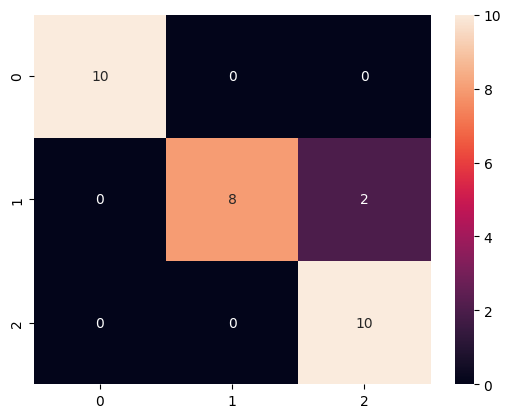

In [ ]:
# importando las bibliotecas necesarias
import numpy as np
from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

# cargando el conjunto de datos de iris que es un dataset multiclase
iris = datasets.load_iris()

# X -> atributos, y -> etiquetas
X = iris.data
y = iris.target

# dividiendo X, y en datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, train_size=0.8, test_size=0.2, stratify=y)

# usar regresión logística para la clasificación
classifier = LogisticRegression(multi_class = "ovr")

# ajustar el modelo para los datos de entrenamiento
classifier.fit(X_train, y_train)
# predecir la variable y para los datos de testeo
prediction_y = classifier.predict(X_test)

# comprobar la precisión del modelo
print("Accuracy:", end=' ')
print(np.sum(prediction_y == y_test) / float(len(y_test)))

# creando una matriz de confusión
cm = confusion_matrix(y_test, prediction_y)
sns.heatmap(cm, annot=True);

## OneVsRest Classifier
Se entrenan N clasificadores binarios, uno por cada clase. Al predecir, cada clasificador estima la probabilidad (o confianza) de que la muestra pertenezca a su clase. La clase que obtiene la mayor probabilidad es la elegida como predicción final.

Accuracy: 0.9333333333333333


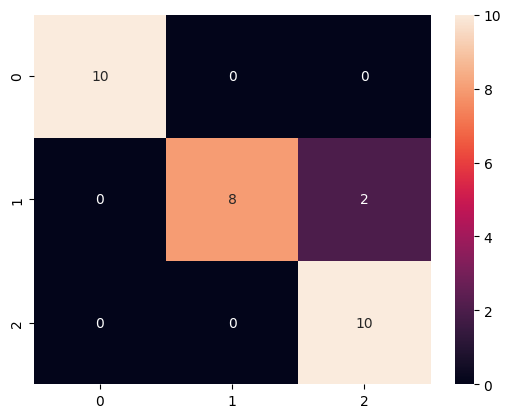

In [ ]:
from sklearn.multiclass import OneVsRestClassifier

classifier = OneVsRestClassifier(LogisticRegression())
classifier.fit(X_train, y_train)
prediction_y = classifier.predict(X_test)

# comprobar la precisión del modelo
print("Accuracy:", end=' ')
print(np.sum(prediction_y == y_test) / float(len(y_test)))

# creando una matriz de confusión
cm = confusion_matrix(y_test, prediction_y)
sns.heatmap(cm, annot=True);

## OneVsOne Classifier
En este caso si tenemos un problema de clasificación multiclase con N clases, se entrenarán $N(N-1)/2$ clasificadores binarios. Durante la predicción, cada uno de los clasificadores binarios vota por una de las dos clases que está intentando discriminar y la clase que recibe la mayoría de votos es la que se predice como la clase final.

Accuracy: 0.9666666666666667


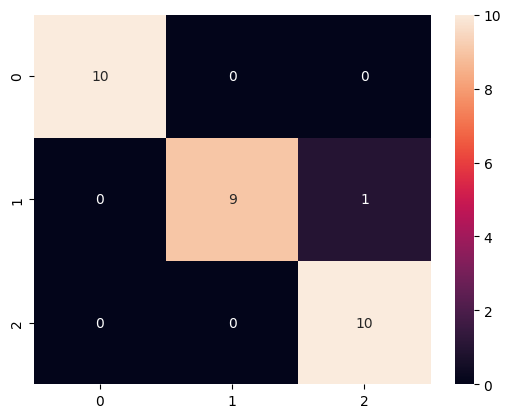

In [ ]:
from sklearn.multiclass import OneVsOneClassifier

classifier = OneVsOneClassifier(LogisticRegression())
classifier.fit(X_train, y_train)
prediction_y = classifier.predict(X_test)

# comprobar la precisión del modelo
print("Accuracy:", end=' ')
print(np.sum(prediction_y == y_test) / float(len(y_test)))

# creando una matriz de confusión
cm = confusion_matrix(y_test, prediction_y)
sns.heatmap(cm, annot=True);

---
# Preguntas

Responda las siguientes preguntas para cada uno de los modelos vistos hoy utilizando el material visto en clase y recurriendo a la documentación de los modelos en scikit-learn:

* ¿El modelo se puede utilizar para ambos problemas: clasificación binario y multiclase? SI
* ¿El modelo implementa algún método o hiperparámetro al cuál la documentación se refiera como "*regularización*" o que me cambie de alguna manera la flexibilidad del modelo construído? LogisticRegresion





---
# Ejercicio Integrador

Consideremos el [dataset](https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik
) de clasificación de tipo de arroz en base a características morfológicas extraidas de imagenes. Descargar el dataset y seguir los siguientes pasos para desarrollar un modelo de clasificación

In [ ]:
# https://archive.ics.uci.edu/static/public/545/rice+cammeo+and+osmancik.zip

!wget https://archive.ics.uci.edu/static/public/545/rice+cammeo+and+osmancik.zip
!unzip rice+cammeo+and+osmancik.zip

--2026-09-15 11:39:05--  https://archive.ics.uci.edu/static/public/545/rice+cammeo+and+osmancik.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘rice+cammeo+and+osmancik.zip’

rice+cammeo+and+osm     [ <=>                ] 167.71K  --.-KB/s    in 0.09s   

2026-09-15 11:39:05 (1.92 MB/s) - ‘rice+cammeo+and+osmancik.zip’ saved [171738]

Archive:  rice+cammeo+and+osmancik.zip
  inflating: Citation_Request.txt    
  inflating: Rice_Cammeo_Osmancik.arff  


In [ ]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from scipy.io import arff
from sklearn.preprocessing import LabelEncoder
arff_file = arff.loadarff('/content/Rice_Cammeo_Osmancik.arff')
df = pd.DataFrame(arff_file[0])

In [ ]:
df

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,b'Cammeo'
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,b'Cammeo'
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,b'Cammeo'
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,b'Cammeo'
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,b'Cammeo'
...,...,...,...,...,...,...,...,...
3805,11441.0,415.858002,170.486771,85.756592,0.864280,11628.0,0.681012,b'Osmancik'
3806,11625.0,421.390015,167.714798,89.462570,0.845850,11904.0,0.694279,b'Osmancik'
3807,12437.0,442.498993,183.572922,86.801979,0.881144,12645.0,0.626739,b'Osmancik'
3808,9882.0,392.296997,161.193985,78.210480,0.874406,10097.0,0.659064,b'Osmancik'


In [ ]:
df['Class'].value_counts()

,count
Class,
b'Osmancik',2180
b'Cammeo',1630


## Ejercicio 1
 Utilizar [LabelEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html) para transformar los valores de las etiquetas y separar los datos aleatoriamente en 2 conjuntos: entrenamiento y evaluación utilizando las proporciones fernet-cola rebajado (80-20). Se puede utilizar la función [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html?highlight=train_test_split#sklearn.model_selection.train_test_split) de scikit-learn. Investigar el efecto del parámetro stratify. ¿Que hace? ¿Es necesario en nuestros datos? Realice gráficos para justificar su respuesta.


In [ ]:
X = df[df.columns.drop('Class')]
y = df['Class']

# Convierto las clases en números enteros
le = LabelEncoder()
y_cod = le.fit_transform(y)


# dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y_cod, test_size=0.2, random_state=42, stratify=y_cod)
# dividir los datos en conjunto de entrenamiento y prueba
X_train_sin, X_test_sin, y_train_sin, y_test_sin = train_test_split(X, y_cod, test_size=0.2, random_state=42)

In [ ]:
clases =df["Class"].value_counts()
target, target_count = np.unique(y_test, return_counts=True)
y_sin_estratificar, y_sin_estratificar_count = np.unique(y_test_sin, return_counts=True)

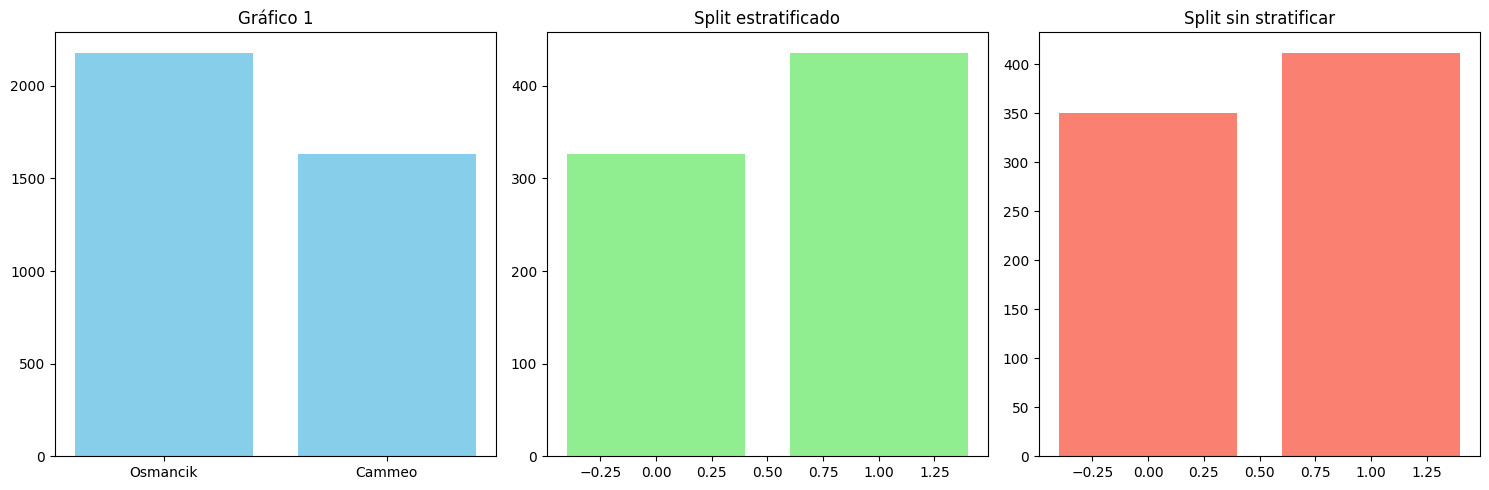

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

# Primer gráfico
ax[0].bar(clases.index,clases, color="skyblue")
ax[0].set_title("Gráfico 1")

# # Segundo gráfico
ax[1].bar(target, target_count, color="lightgreen")
ax[1].set_title("Split estratificado")

# # Tercer gráfico
ax[2].bar(y_sin_estratificar, y_sin_estratificar_count, color="salmon")
ax[2].set_title("Split sin stratificar")

# Ajustar espacios
plt.tight_layout()
plt.show()

## Ejercicio 2
2) Elegir un hiperparámetro para cada modelo: regresión logística, SVM y KNN. Para cada modelo definir una grilla para ese hiperparámetro (no tienen porque ser muchos). Elija el mejor valor de dicho hiperparámetro utilizando `Cross Validation` en el conjunto de entrenamiento para `f1-score`. Una vez elegido ese mejor modelo, reentrene el modelo en todo el conjunto de entrenamiento.
*Hint1:* Puede ser de utilidad utilizar la función [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

########################################
# crear el modelo de regresión logística
########################################
reg_log = LogisticRegression()

# Versión con GridSearchCV
param_grid = {
    'max_iter': [100, 1000, 5000, 10000],
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid_search = GridSearchCV(reg_log, param_grid=param_grid, scoring="f1", cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters Regresion Logistica:", grid_search.best_params_)
print("Best Estimator Regresion Logistica:", grid_search.best_estimator_)



######################
# crear el modelo KNN
#######################
model_KNN = KNeighborsClassifier()

# Versión con GridSearchCV
param_grid = {
    "n_neighbors": [3, 5, 7, 11, 15],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2]  # solo si metric="minkowski"
}

grid_search = GridSearchCV(model_KNN, param_grid=param_grid, scoring="f1", cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters KNN:", grid_search.best_params_)
print("Best Estimator KNN:", grid_search.best_estimator_)


Best Parameters Regresion Logistica: {'C': 0.01, 'max_iter': 1000}
Best Estimator Regresion Logistica: LogisticRegression(C=0.01, max_iter=1000)
Best Parameters KNN: {'metric': 'manhattan', 'n_neighbors': 5, 'p': 1, 'weights': 'uniform'}
Best Estimator KNN: KNeighborsClassifier(metric='manhattan', p=1)


In [ ]:

######################
# crear el modelo SVM
#######################
model_SVM = SVC(random_state=42)

# Versión con GridSearchCV
param_grid = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["linear", "rbf", "poly"],
    #"gamma": ["scale", "auto", 0.01, 0.1, 1],
    #"degree": [2, 3, 4]   # solo aplica si kernel="poly"
}

# entrenar el modelo con los datos de entrenamiento
model_SVM.fit(X_train, y_train)

grid_search = GridSearchCV(model_SVM, param_grid=param_grid, scoring="f1", cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters SVM:", grid_search.best_params_)
print("Best Estimator SVM:", grid_search.best_estimator_)


Best Parameters SVM: {'C': 10, 'kernel': 'linear'}
Best Estimator SVM: SVC(C=10, kernel='linear', random_state=42)


## Ejercicio 3
3) (*Opcional*) KNN es un modelo que es muy sensible a las escalas diferentes en las features, instancie un [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) y transforme las variables para centrarlas y que tengan el mismo desvío (pueden verificarlo usando un `describe` de su `dataframe`), cree un nuevo modelo KNN, elija su mejor valor para K usando de nuevo `f1`.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
data_train = pd.DataFrame(X_train_scaled, columns=X_train.columns)
data_train.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3.048000e+03,3.048000e+03,3.048000e+03,3.048000e+03,3.048000e+03,3.048000e+03,3.048000e+03
mean,2.913971e-16,4.062076e-16,4.726461e-16,7.284928e-16,2.628402e-16,1.456986e-16,6.270866e-16
std,1.000164e+00,1.000164e+00,1.000164e+00,1.000164e+00,1.000164e+00,1.000164e+00,1.000164e+00
min,-2.965733e+00,-2.669159e+00,-2.483838e+00,-4.706428e+00,-5.204531e+00,-2.953431e+00,-2.127038e+00
25%,-7.512822e-01,-7.904915e-01,-8.299182e-01,-6.130108e-01,-7.084417e-01,-7.530910e-01,-8.225496e-01
50%,-1.328553e-01,-1.475443e-01,-1.626170e-01,1.830545e-02,1.071735e-01,-1.262335e-01,-2.034658e-01
75%,7.575521e-01,8.360997e-01,8.656760e-01,6.619153e-01,7.578106e-01,7.646084e-01,8.492857e-01
max,3.605757e+00,2.635455e+00,2.869176e+00,3.703526e+00,2.924201e+00,3.456574e+00,2.570102e+00


<Axes: ylabel='Frequency'>

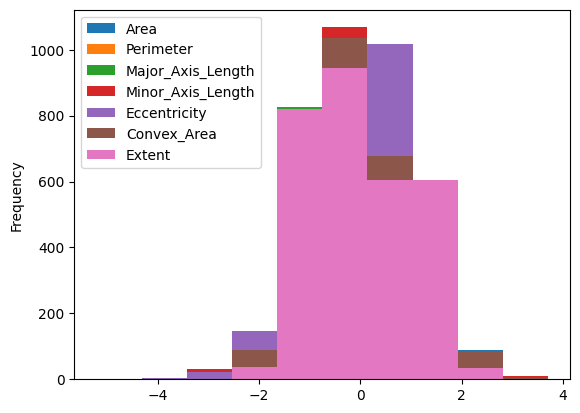

In [ ]:
data_train.plot(kind="hist")

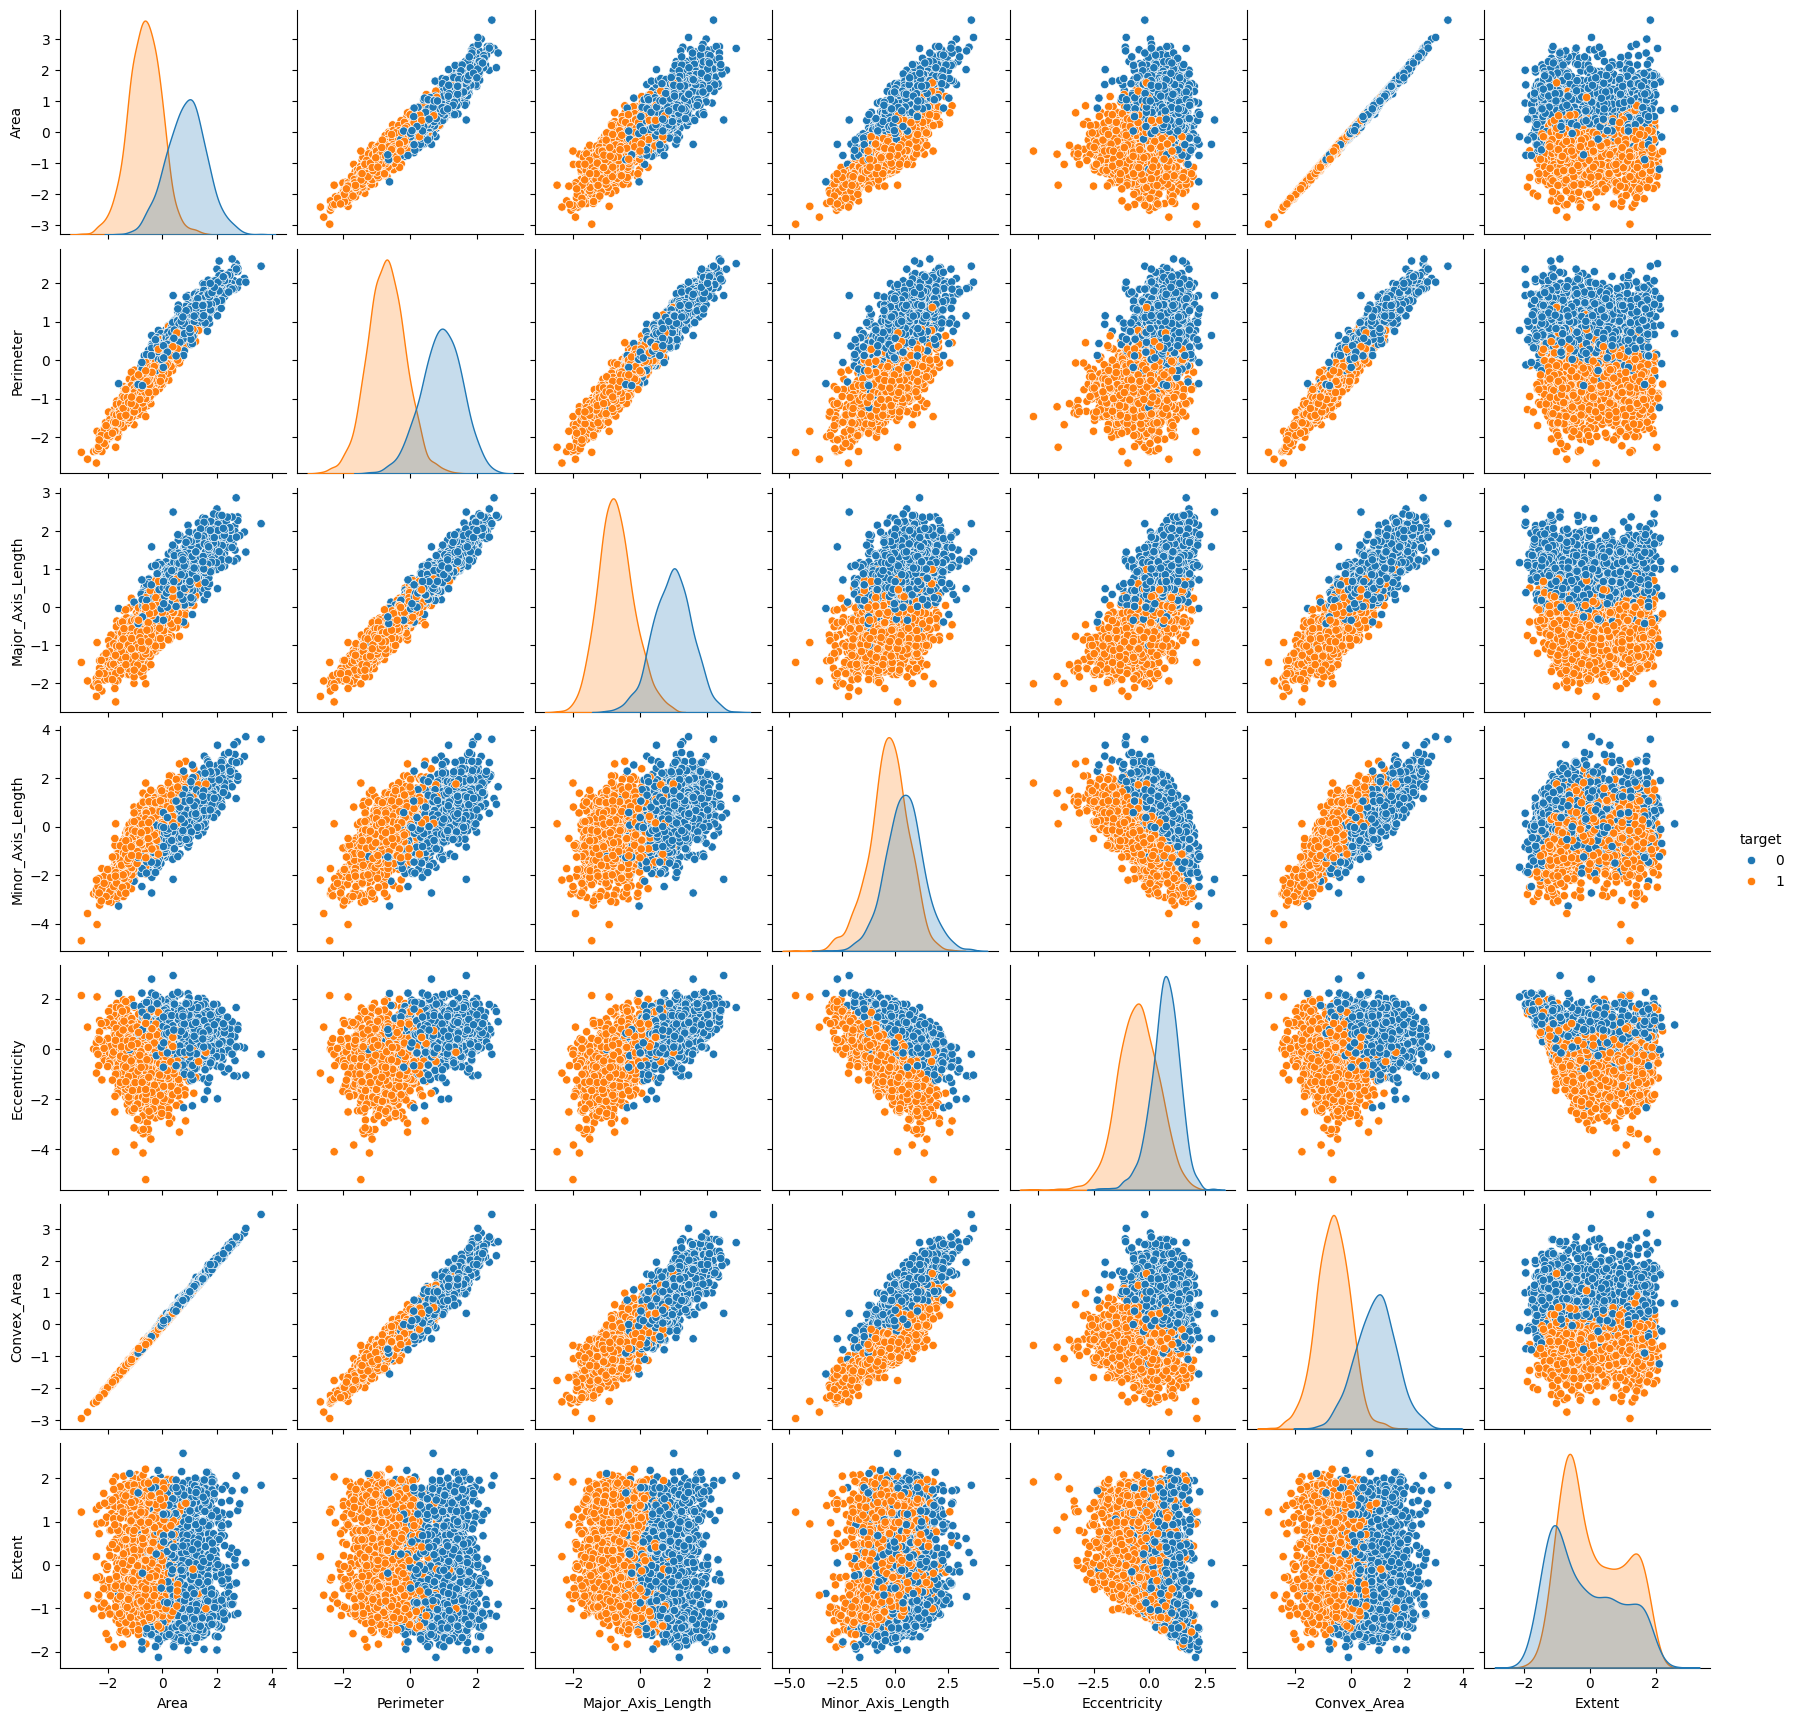

In [ ]:
# data_train.plot(kind="scatter", x="Area", y="Extent")
data_train["target"] = y_train
sns.pairplot(data_train, hue="target")

In [ ]:
######################
# crear el modelo KNN
#######################
model_KNN = KNeighborsClassifier()

# Versión con GridSearchCV
param_grid = {
    "n_neighbors": [3, 5, 7, 11, 15],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2]  # solo si metric="minkowski"
}

grid_search = GridSearchCV(model_KNN, param_grid=param_grid, scoring="f1", cv=5, n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print("Best Parameters KNN:", grid_search.best_params_)
print("Best Estimator KNN:", grid_search.best_estimator_)

Best Parameters KNN: {'metric': 'euclidean', 'n_neighbors': 11, 'p': 1, 'weights': 'uniform'}
Best Estimator KNN: KNeighborsClassifier(metric='euclidean', n_neighbors=11, p=1)


## Ejercicio 4
4) Analizar el `accuracy_score` que se obtiene para los distintos modelos en el conjunto de test. Realizar un grafico en el cual se observen los valores de accuracy y F1 score macro para cada mejor modelo encontrado. ¿Cuál fue el mejor modelo? Compare las matrices de confusiones, ¿qué modelo eligirían si les interesara solo la [precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html)?


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# crear el modelo de KNN con k=5
model_KNN = KNeighborsClassifier(metric='euclidean', n_neighbors= 11, p= 1, weights= 'uniform')

# entrenar el modelo con los datos de entrenamiento
model_KNN.fit(X_train_scaled, y_train)

# hacer predicciones con los datos de prueba
y_pred = model_KNN.predict(X_test_scaled)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("precision de la clasificación: {:.2f}%".format(precision * 100))
print("recall de la clasificación: {:.2f}%".format(recall * 100))
print("f1 de la clasificación: {:.2f}%".format(f1 * 100))


Accuracy de la clasificación: 91.21%
precision de la clasificación: 91.12%
recall de la clasificación: 90.88%
f1 de la clasificación: 91.00%


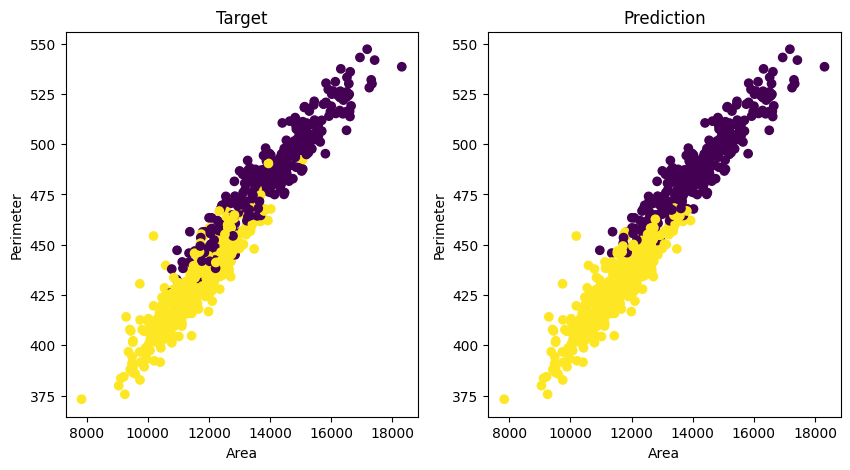

In [ ]:
X_test["target"] = y_test
X_test["prediction"] = y_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.scatter(X_test["Area"], X_test["Perimeter"], c=X_test["target"], cmap="viridis")
ax1.set_xlabel("Area")
ax1.set_ylabel("Perimeter")
ax1.set_title("Target")

ax2.scatter(X_test["Area"], X_test["Perimeter"], c=X_test["prediction"], cmap="viridis")
ax2.set_xlabel("Area")
ax2.set_ylabel("Perimeter")
ax2.set_title("Prediction")

plt.show()


5) (*Importante*) En los modelos considerados existen hiperparámetros que regulan la flexibilidad/complejidad del modelo. Piensen cuál podría ser útil para este rol, y grafiquen la curva de complejidad asociada. Hagan un diagnostico del sobreajuste y seleccionen valores de hiperparámetros óptimos